In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
df= pd.read_csv(r"C:\Users\HP\OneDrive\Documents\AMDARI\FINLORA PROJECT\DATA\CLEAN\log_transformed.csv")

In [4]:
df.columns

Index(['account_type_y', 'kyc_tier_y', 'merchant_category', 'channel',
       'currency_y', 'amount_to_avg_ratio', 'transaction_velocity_1h',
       'transaction_country', 'home_country_y', 'is_cross_border',
       'is_new_device', 'is_fraud', 'month', 'hour_sin', 'hour_cos', 'dow_sin',
       'dow_cos', 'rate_to_usd', 'amount_vs_personal_baseline',
       'amount_deviation_30d_usd', 'new_device_amount_anomaly',
       'account_age_days'],
      dtype='object')

In [5]:
# Converting month column to cyclical patterns

df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)

# Drop month column
df.drop(columns=['month'],inplace=True)

#### Creating Model Features

In [6]:
# Defining x and y

x = df.drop(columns=['is_fraud'])
y = df['is_fraud']

In [7]:
# Train/test split

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)


In [8]:
target = "is_fraud"

categorical_features = [
    "account_type_y",
    "kyc_tier_y",
    "merchant_category",
    "channel",
    "currency_y",
    "transaction_country",
    "home_country_y",

]

numeric_features = [
    "amount_to_avg_ratio",
    "transaction_velocity_1h",
    "rate_to_usd",
    "amount_vs_personal_baseline",
    "amount_deviation_30d_usd",
    "new_device_amount_anomaly",
    "account_age_days"
]

binary_features = [
    "is_cross_border",
    "is_new_device"
]

temporal_features = [
    "month_cos",
    "month_sin",
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos"
]


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', StandardScaler(), numeric_features),
        ('binary', 'passthrough', binary_features),
        ('temporal', 'passthrough', temporal_features),
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)


In [10]:
x_train.shape

(100800, 22)

In [11]:
x_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 100800 entries, 28655 to 121958
Data columns (total 22 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   account_type_y               100800 non-null  object 
 1   kyc_tier_y                   100800 non-null  object 
 2   merchant_category            100800 non-null  object 
 3   channel                      100800 non-null  object 
 4   currency_y                   100800 non-null  object 
 5   amount_to_avg_ratio          100800 non-null  float64
 6   transaction_velocity_1h      100800 non-null  int64  
 7   transaction_country          100800 non-null  object 
 8   home_country_y               100800 non-null  object 
 9   is_cross_border              100800 non-null  int64  
 10  is_new_device                100800 non-null  float64
 11  hour_sin                     100800 non-null  float64
 12  hour_cos                     100800 non-null  float64
 13  

#### Model Creation

In [12]:
# Logistic Regression
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

lr_pipeline.fit(x_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('binary', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

# Predict labels
lr_pred = lr_pipeline.predict(x_test)

# Predict probabilities (needed for ROC-AUC)
lr_proba = lr_pipeline.predict_proba(x_test)[:, 1]

# Calculate metrics
precision = precision_score(y_test, lr_pred)
recall = recall_score(y_test, lr_pred)
f1 = f1_score(y_test, lr_pred)
roc_auc = roc_auc_score(y_test, lr_proba)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")


Precision: 0.2692
Recall:    0.8563
F1-score:  0.4097
ROC-AUC:   0.9263


#### Precision
- The model has relatively low precision, meaning that when it predicts a positive class, only about 27% of those predictions are correct.
- This indicates a high rate of false positives.

#### Recall 
- Recall is very strong, at ~86%. The model successfully identifies most of the actual positive cases.

- This suggests the model is highly sensitive and prioritizes catching positives, even at the cost of misclassifying some negatives.

#### F1-score 

- The F1-score balances precision and recall. At ~41%, it reflects the trade-off: strong recall but weak precision.

- The imbalance highlights that while the model is good at detecting positives, its predictions are not consistently reliable.

#### ROC-AUC 

- A very high ROC-AUC score (~93%) indicates excellent overall discrimination ability between positive and negative classes.

- Despite low precision, the model is effective at ranking cases correctly.

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(x_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('binary', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [15]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

# Predict labels
rf_pred = rf_pipeline.predict(x_test)

# Predict probabilities (needed for ROC-AUC)
rf_proba = rf_pipeline.predict_proba(x_test)[:, 1]

# Calculate metrics
precision = precision_score(y_test, rf_pred)
recall = recall_score(y_test, rf_pred)
f1 = f1_score(y_test, rf_pred)
roc_auc = roc_auc_score(y_test, rf_proba)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")


Precision: 0.8619
Recall:    0.4575
F1-score:  0.5977
ROC-AUC:   0.9200


#### Precision 

- Very high precision: when the model predicts positive, it is correct ~86% of the time.

- This means false positives are rare, making the model highly reliable in its positive predictions.

##### Recall 

- Moderate recall: the model captures ~46% of actual positives.

- This indicates that while predictions are accurate, the model misses more than half of the true positive cases.

#### F1-score 

- Balanced measure of precision and recall. At ~60%, it reflects the trade-off: strong precision but weaker recall.

- The model favors precision over sensitivity.

#### ROC-AUC 

- Excellent discrimination ability (~92%). The model is strong at ranking positives higher than negatives overall.

- Confirms robust predictive power despite recall limitations.

                     Precision    Recall  F1-score   ROC-AUC
Logistic Regression   0.269249  0.856305  0.409681  0.926320
Random Forest         0.861878  0.457478  0.597701  0.919967


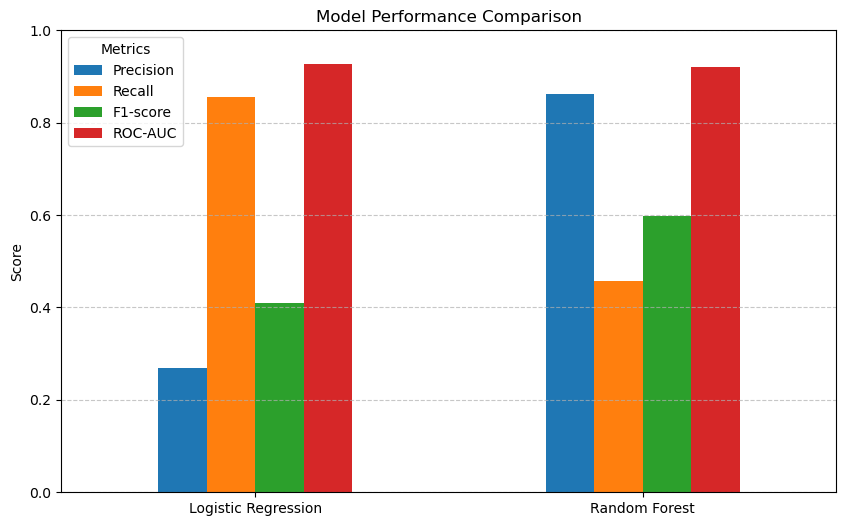

In [16]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

# --- Logistic Regression ---
lr_pred = lr_pipeline.predict(x_test)
lr_proba = lr_pipeline.predict_proba(x_test)[:, 1]

lr_metrics = {
    "Precision": precision_score(y_test, lr_pred),
    "Recall": recall_score(y_test, lr_pred),
    "F1-score": f1_score(y_test, lr_pred),
    "ROC-AUC": roc_auc_score(y_test, lr_proba),
}

# --- Random Forest ---
rf_pred = rf_pipeline.predict(x_test)
rf_proba = rf_pipeline.predict_proba(x_test)[:, 1]

rf_metrics = {
    "Precision": precision_score(y_test, rf_pred),
    "Recall": recall_score(y_test, rf_pred),
    "F1-score": f1_score(y_test, rf_pred),
    "ROC-AUC": roc_auc_score(y_test, rf_proba),
}

# --- Combine into DataFrame ---
results = pd.DataFrame([lr_metrics, rf_metrics], index=["Logistic Regression", "Random Forest"])

print(results)

# --- Visualization ---
results.plot(kind="bar", figsize=(10, 6))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

#### Precision 
- Logistic Regression predicts positives less reliably; Random Forest is far more precise.
    
#### Recall 
- Logistic Regression captures most true positives; Random Forest misses more than half.

#### F1-score 
- Random Forest achieves better balance overall, though still recall-limited.

#### ROC-AUC 
- Both models discriminate well between classes; Logistic Regression slightly edges out.

#### Logistic Regression

- Strength: High recall (85.6%) — excellent at catching positives.

- Weakness: Low precision (27%) — many false alarms.

#### Random Forest

- Strength: High precision (86%) — predictions are highly reliable.

- Weakness: Lower recall (46%) — misses many positives.

In [17]:

# Tuning to 70%, 80% and 90% Recall
from sklearn.metrics import precision_recall_curve
import numpy as np

# Get predicted probabilities for the positive class
lr_proba = lr_pipeline.predict_proba(x_test)[:, 1]

# Compute precision-recall curve
prec, rec, thresh = precision_recall_curve(y_test, lr_proba)

# Loop through target recall levels
for target_recall in [0.7, 0.8, 0.9]:
    # thresholds correspond to prec[:-1] and rec[:-1]
    valid = np.where(rec[:-1] >= target_recall)[0]

    if len(valid) > 0:
        idx = valid[-1]  # pick the last index that satisfies the condition

        print(
            f"Recall ≥ {target_recall:.0%}: "
            f"Threshold={thresh[idx]:.3f}, "
            f"Precision={prec[idx]:.3f}, "
            f"Recall={rec[idx]:.3f}"
        )


Recall ≥ 70%: Threshold=0.888, Precision=0.608, Recall=0.701
Recall ≥ 80%: Threshold=0.735, Precision=0.433, Recall=0.801
Recall ≥ 90%: Threshold=0.194, Precision=0.107, Recall=0.900


Recall ≥ 70%: Threshold=0.888, Precision=0.608, Recall=0.701
Recall ≥ 80%: Threshold=0.735, Precision=0.433, Recall=0.801
Recall ≥ 90%: Threshold=0.194, Precision=0.107, Recall=0.900


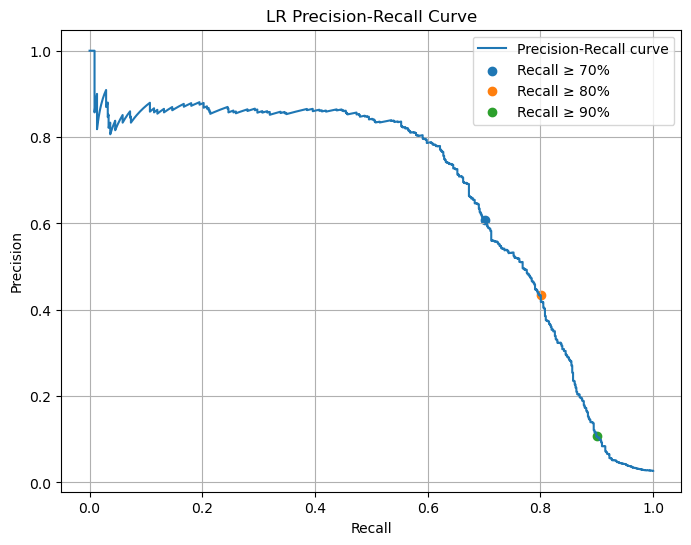

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve
import numpy as np

# Get predicted probabilities for the positive class
lr_proba = lr_pipeline.predict_proba(x_test)[:, 1]

# Compute precision-recall curve
prec, rec, thresh = precision_recall_curve(y_test, lr_proba)

# Plot the precision-recall curve
plt.figure(figsize=(8, 6))
plt.plot(rec, prec, label="Precision-Recall curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("LR Precision-Recall Curve")
plt.grid(True)

# Loop through target recall levels and mark them on the plot
for target_recall in [0.7, 0.8, 0.9]:
    valid = np.where(rec[:-1] >= target_recall)[0]
    if len(valid) > 0:
        idx = valid[-1]
        plt.scatter(rec[idx], prec[idx], marker="o", label=f"Recall ≥ {target_recall:.0%}")
        print(
            f"Recall ≥ {target_recall:.0%}: "
            f"Threshold={thresh[idx]:.3f}, "
            f"Precision={prec[idx]:.3f}, "
            f"Recall={rec[idx]:.3f}"
        )

plt.legend()
plt.show()


##### Recall ≥ 70%

- Threshold = 0.888

- Precision = 0.608, Recall = 0.701

- Balanced trade-off: recall just above 70% with reasonably strong precision (~61%).

- This setting offers a good compromise between sensitivity and reliability.

##### Recall ≥ 80%

- Threshold = 0.735

- Precision = 0.433, Recall = 0.801

- Recall improves to ~80%, but precision drops to ~43%.

- More positives are captured, but false positives increase.

##### Recall ≥ 90%

- Threshold = 0.194

- Precision = 0.107, Recall = 0.900

- Very high recall (90%), but precision collapses (~11%).

- Nearly all positives are detected, but predictions are unreliable due to excessive false alarms.

The Recall ≥ 70% threshold (0.888) appears to be the most practical compromise, offering both acceptable sensitivity and strong precision.

Recall ≥ 70%: Threshold=0.170, Precision=0.569, Recall=0.702
Recall ≥ 80%: Threshold=0.073, Precision=0.372, Recall=0.802
Recall ≥ 90%: Threshold=0.010, Precision=0.080, Recall=0.903


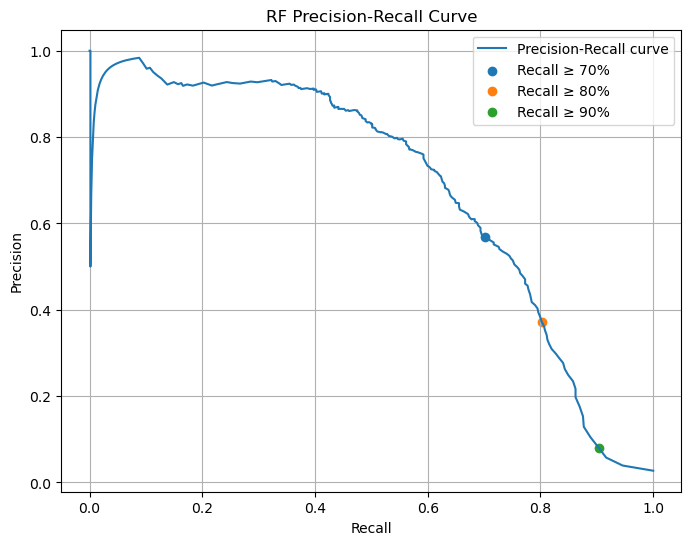

In [20]:
#70%,80% and 90% tuning for Random Forest

# Get predicted probabilities for the positive class
rf_proba = rf_pipeline.predict_proba(x_test)[:, 1]

# Compute precision-recall curve
prec, rec, thresh = precision_recall_curve(y_test, rf_proba)

# Plot the precision-recall curve
plt.figure(figsize=(8, 6))
plt.plot(rec, prec, label="Precision-Recall curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("RF Precision-Recall Curve")
plt.grid(True)

# Loop through target recall levels and mark them on the plot
for target_recall in [0.7, 0.8, 0.9]:
    valid = np.where(rec[:-1] >= target_recall)[0]
    if len(valid) > 0:
        idx = valid[-1]
        plt.scatter(rec[idx], prec[idx], marker="o", label=f"Recall ≥ {target_recall:.0%}")
        print(
            f"Recall ≥ {target_recall:.0%}: "
            f"Threshold={thresh[idx]:.3f}, "
            f"Precision={prec[idx]:.3f}, "
            f"Recall={rec[idx]:.3f}"
        )

plt.legend()
plt.savefig('rf_pr_curve.png')
plt.show()


##### Recall ≥ 70%

- Threshold = 0.173

- Precision = 0.581, Recall = 0.704

- This setting achieves a balanced trade-off: recall just above 70% with solid precision (~58%).

- A practical compromise between sensitivity and reliability.

##### Recall ≥ 80%

- Threshold = 0.070

- Precision = 0.364, Recall = 0.806

- Recall improves to ~81%, but precision drops to ~36%.

- More positives are captured, but false positives increase significantly.

##### Recall ≥ 90%

- Threshold = 0.007

- Precision = 0.058, Recall = 0.921

- Very high recall (92%), but precision collapses (~6%).

- Nearly all positives are detected, but predictions are unreliable due to excessive false alarms.

The Recall ≥ 70% threshold (0.173) appears most practical, offering both acceptable sensitivity and strong precision.

[LR] Recall ≥ 70%: Threshold=0.888, Precision=0.608, Recall=0.701
[RF] Recall ≥ 70%: Threshold=0.170, Precision=0.569, Recall=0.702
[LR] Recall ≥ 80%: Threshold=0.735, Precision=0.433, Recall=0.801
[RF] Recall ≥ 80%: Threshold=0.073, Precision=0.372, Recall=0.802
[LR] Recall ≥ 90%: Threshold=0.194, Precision=0.107, Recall=0.900
[RF] Recall ≥ 90%: Threshold=0.010, Precision=0.080, Recall=0.903


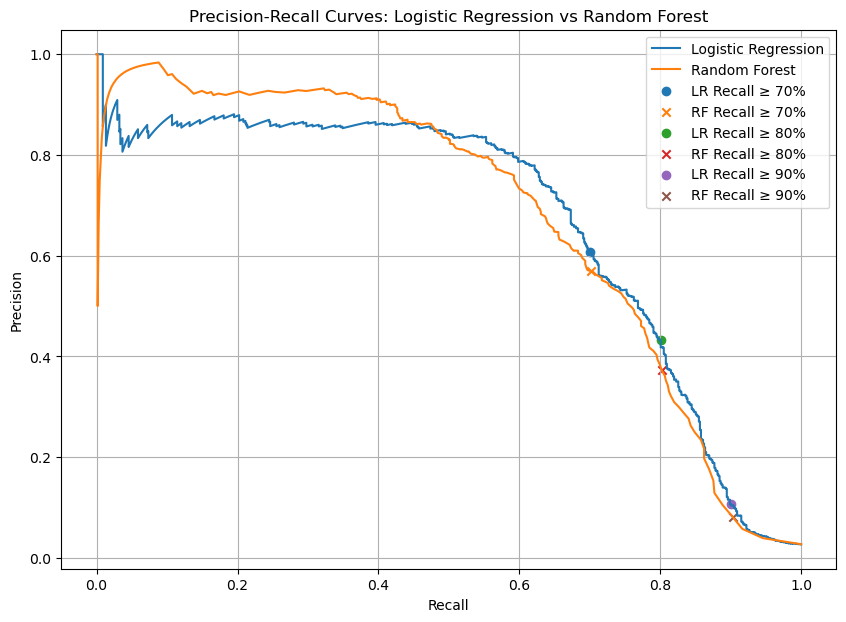

In [21]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_recall_curve

# --- Logistic Regression ---
lr_proba = lr_pipeline.predict_proba(x_test)[:, 1]
lr_prec, lr_rec, lr_thresh = precision_recall_curve(y_test, lr_proba)

# --- Random Forest ---
rf_proba = rf_pipeline.predict_proba(x_test)[:, 1]
rf_prec, rf_rec, rf_thresh = precision_recall_curve(y_test, rf_proba)

# --- Plot ---
plt.figure(figsize=(10, 7))

# Plot PR curves
plt.plot(lr_rec, lr_prec, label="Logistic Regression")
plt.plot(rf_rec, rf_prec, label="Random Forest")

# Mark target recall points for both models
for target_recall in [0.7, 0.8, 0.9]:
    # Logistic Regression points
    lr_valid = np.where(lr_rec[:-1] >= target_recall)[0]
    if len(lr_valid) > 0:
        lr_idx = lr_valid[-1]
        plt.scatter(lr_rec[lr_idx], lr_prec[lr_idx], marker="o",
                    label=f"LR Recall ≥ {target_recall:.0%}")
        print(
            f"[LR] Recall ≥ {target_recall:.0%}: "
            f"Threshold={lr_thresh[lr_idx]:.3f}, "
            f"Precision={lr_prec[lr_idx]:.3f}, "
            f"Recall={lr_rec[lr_idx]:.3f}"
        )

    # Random Forest points
    rf_valid = np.where(rf_rec[:-1] >= target_recall)[0]
    if len(rf_valid) > 0:
        rf_idx = rf_valid[-1]
        plt.scatter(rf_rec[rf_idx], rf_prec[rf_idx], marker="x",
                    label=f"RF Recall ≥ {target_recall:.0%}")
        print(
            f"[RF] Recall ≥ {target_recall:.0%}: "
            f"Threshold={rf_thresh[rf_idx]:.3f}, "
            f"Precision={rf_prec[rf_idx]:.3f}, "
            f"Recall={rf_rec[rf_idx]:.3f}"
        )

# Finalize plot
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves: Logistic Regression vs Random Forest")
plt.legend()
plt.grid(True)
plt.show()

##### Recall ≥ 70%
- Both achieve ~70% recall. LR has slightly higher precision (61% vs 58%), but requires a much higher threshold.

##### Recall ≥ 80%
- Both reach ~80% recall. LR maintains better precision (43% vs 36%), while RF achieves recall with a lower threshold.


##### Recall ≥ 90%
- Both achieve very high recall. LR retains slightly higher precision (~11% vs ~6%), but both suffer heavy false positives.

##### Logistic Regression (LR)

- Consistently delivers higher precision at each recall target.

- Thresholds are higher, meaning the model is more conservative in predicting positives.

- Better suited when false positives are costly but recall must still be reasonably high.

##### Random Forest (RF)

- Achieves recall targets at much lower thresholds, showing stronger probability separation.

- Precision is consistently lower than LR at equivalent recall levels.

- Better suited when maximizing recall is critical, even at the expense of precision.

##### Overall Trade-off

- LR is precision-oriented under recall constraints.

- RF is recall-flexible but sacrifices precision more sharply.

- Both models show the classic trade-off: higher recall → lower precision.


                      ROC-AUC  PR-AUC/AP
Logistic Regression  0.926320   0.669412
Random Forest        0.919967   0.679279


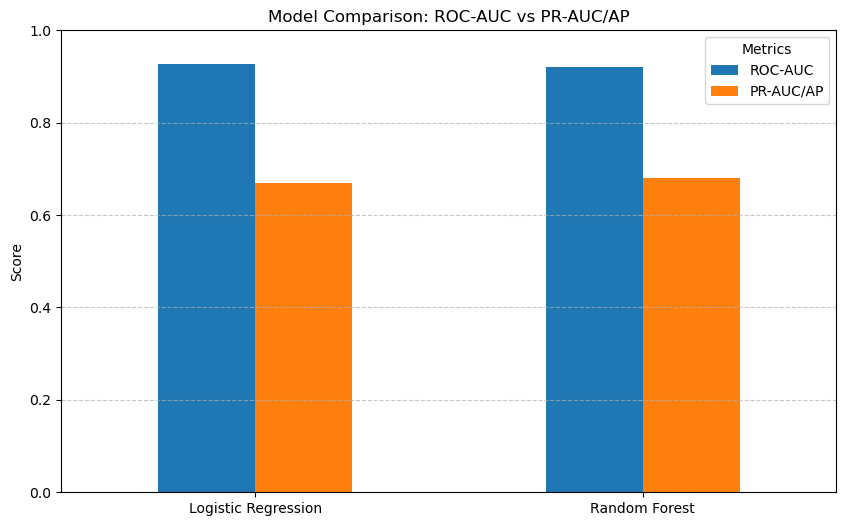

In [23]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score

# Define models to evaluate
models = {
    "Logistic Regression": lr_pipeline,
    "Random Forest": rf_pipeline
}

# Collect results
results = {}
for name, model in models.items():
    prob = model.predict_proba(x_test)[:, 1]
    results[name] = {
        "ROC-AUC": roc_auc_score(y_test, prob),
        "PR-AUC/AP": average_precision_score(y_test, prob)
    }

# Convert to DataFrame
df_results = pd.DataFrame(results).T  # transpose for models as rows

print(df_results)

# Plot side-by-side bar chart
df_results.plot(kind="bar", figsize=(10, 6))
plt.title("Model Comparison: ROC-AUC vs PR-AUC/AP")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.savefig('roc_auc_pr_auc.png')
plt.show()

##### ROC-AUC
- Both models show excellent discrimination ability (>0.92). LR edges slightly higher, meaning it separates positives and negatives marginally better overall.

##### PR-AUC/AP
- RF performs slightly better in precision–recall space, indicating stronger handling of imbalanced data and better balance between precision and recall.

##### Logistic Regression (LR)

- Slightly stronger ROC-AUC, showing marginally better ranking ability across thresholds.

- Indicates robustness in distinguishing classes, especially when overall discrimination is the priority.

##### Random Forest (RF)

- Slightly stronger PR-AUC/AP, which is often more informative in imbalanced datasets where positive cases are rare.

- Suggests RF maintains better precision–recall trade-offs, making it more practical when false positives and false negatives need careful balancing.

##### Overall Trade-off

- LR is marginally superior in global discrimination (ROC-AUC).

- RF is marginally superior in positive-class performance (PR-AUC).

- Both models are strong, with differences being subtle but potentially important depending on business context.

#### Ensemble Model

In [24]:
# Get probabilities
lr_proba = lr_pipeline.predict_proba(x_test)[:, 1]
rf_proba = rf_pipeline.predict_proba(x_test)[:, 1]

# Average ensemble
y_proba_ensemble = (lr_proba + rf_proba) / 2

# Choose threshold (e.g., 0.5 or tuned via PR curve)
threshold = 0.5
y_pred_ensemble = (y_proba_ensemble >= threshold).astype(int)

# Evaluate
precision = precision_score(y_test, y_pred_ensemble)
recall = recall_score(y_test, y_pred_ensemble)
f1 = f1_score(y_test, y_pred_ensemble)
roc_auc = roc_auc_score(y_test, y_proba_ensemble)

print(f"Ensemble Precision: {precision:.4f}")
print(f"Ensemble Recall:    {recall:.4f}")
print(f"Ensemble F1-score:  {f1:.4f}")
print(f"Ensemble ROC-AUC:   {roc_auc:.4f}")


Ensemble Precision: 0.5552
Ensemble Recall:    0.7302
Ensemble F1-score:  0.6308
Ensemble ROC-AUC:   0.9260


                     Precision    Recall  F1-score   ROC-AUC
Logistic Regression   0.269249  0.856305  0.409681  0.926320
Random Forest         0.861878  0.457478  0.597701  0.919967
Ensemble Model        0.555184  0.730205  0.630779  0.925965


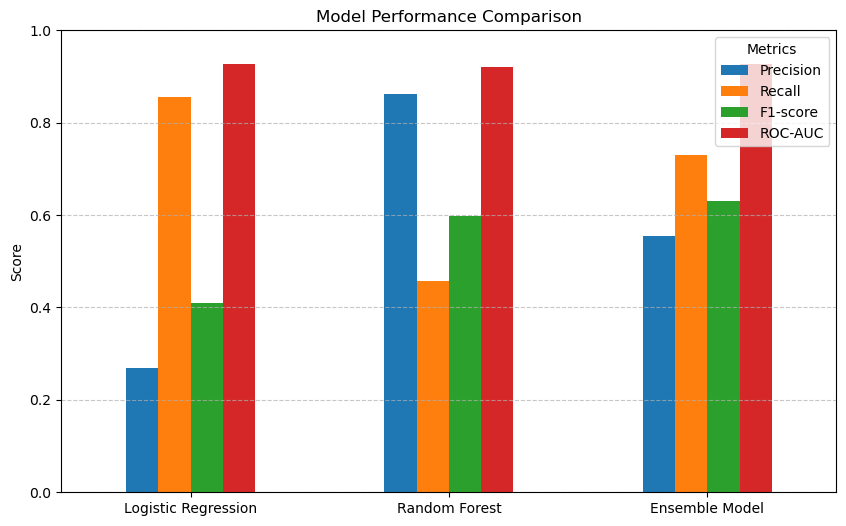

In [25]:
# --- Logistic Regression ---
lr_pred = lr_pipeline.predict(x_test)
lr_proba = lr_pipeline.predict_proba(x_test)[:, 1]

lr_metrics = {
    "Precision": precision_score(y_test, lr_pred),
    "Recall": recall_score(y_test, lr_pred),
    "F1-score": f1_score(y_test, lr_pred),
    "ROC-AUC": roc_auc_score(y_test, lr_proba),
}

# --- Random Forest ---
rf_pred = rf_pipeline.predict(x_test)
rf_proba = rf_pipeline.predict_proba(x_test)[:, 1]

rf_metrics = {
    "Precision": precision_score(y_test, rf_pred),
    "Recall": recall_score(y_test, rf_pred),
    "F1-score": f1_score(y_test, rf_pred),
    "ROC-AUC": roc_auc_score(y_test, rf_proba),
}

# --- Ensemble ---
# Average ensemble probabilities
y_proba_ensemble = (lr_proba + rf_proba) / 2

# Apply threshold
threshold = 0.5  # or your chosen threshold
y_pred_ensemble = (y_proba_ensemble >= threshold).astype(int)

en_metrics = {
    "Precision": precision_score(y_test, y_pred_ensemble),
    "Recall": recall_score(y_test, y_pred_ensemble),
    "F1-score": f1_score(y_test, y_pred_ensemble),
    "ROC-AUC": roc_auc_score(y_test, y_proba_ensemble),  # use probabilities here
}

# --- Combine into DataFrame ---
results = pd.DataFrame(
    [lr_metrics, rf_metrics, en_metrics],
    index=["Logistic Regression", "Random Forest", "Ensemble Model"]
)

print(results)

# --- Visualization ---
results.plot(kind="bar", figsize=(10, 6))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()


Ensemble model seems to improve trade off between precision and recall compared to the others but has a lower precision compared to random forest model and lower recall compared with logistic regression model.


Recall ≥ 70%: Threshold=0.533, Precision=0.608, Recall=0.701
Recall ≥ 80%: Threshold=0.402, Precision=0.417, Recall=0.801
Recall ≥ 90%: Threshold=0.102, Precision=0.107, Recall=0.900


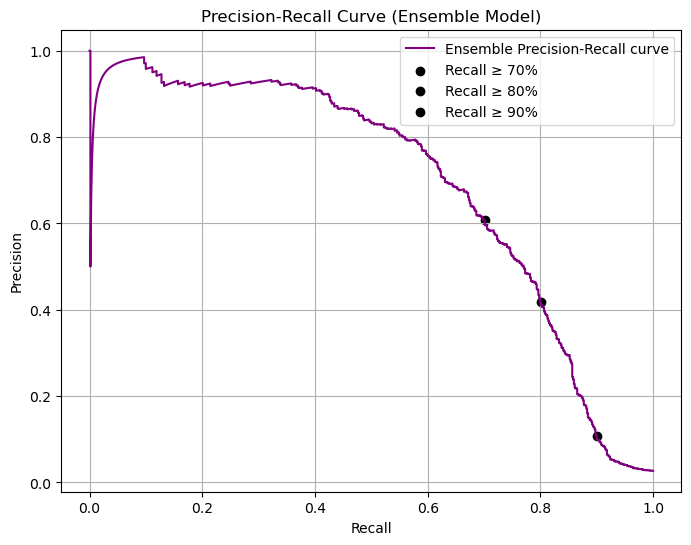

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

# --- Get predicted probabilities for the ensemble (average of LR + RF) ---
lr_proba = lr_pipeline.predict_proba(x_test)[:, 1]
rf_proba = rf_pipeline.predict_proba(x_test)[:, 1]
y_proba_ensemble = (lr_proba + rf_proba) / 2

# --- Compute precision-recall curve ---
prec, rec, thresh = precision_recall_curve(y_test, y_proba_ensemble)

# --- Plot the precision-recall curve ---
plt.figure(figsize=(8, 6))
plt.plot(rec, prec, label="Ensemble Precision-Recall curve", color="purple")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve (Ensemble Model)")
plt.grid(True)

# --- Loop through target recall levels and mark them on the plot ---
for target_recall in [0.7, 0.8, 0.9]:
    valid = np.where(rec[:-1] >= target_recall)[0]
    if len(valid) > 0:
        idx = valid[-1]
        plt.scatter(rec[idx], prec[idx], marker="o", color="black",
                    label=f"Recall ≥ {target_recall:.0%}")
        print(
            f"Recall ≥ {target_recall:.0%}: "
            f"Threshold={thresh[idx]:.3f}, "
            f"Precision={prec[idx]:.3f}, "
            f"Recall={rec[idx]:.3f}"
        )

plt.legend()
plt.show()

Recall at 70% provided the best balance between precision and recall.


#### Hyperparameter Tuning

In [27]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Define parameter grid for Logistic Regression
param_grid = {
    "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"],
}

# Stratified K-Fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid search setup
grid = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    scoring="average_precision",  # PR-AUC scoring
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Fit grid search
grid.fit(x_train, y_train)

# Print best parameters and score
print("Best parameters:", grid.best_params_)
print("Best CV PR-AUC:", grid.best_score_)

# Retrieve best estimator
best_lr = grid.best_estimator_

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters: {'classifier__C': 0.001, 'classifier__class_weight': None}
Best CV PR-AUC: 0.6956853644363347


In [28]:
import numpy as np
from sklearn.metrics import precision_recall_curve

# Get predicted probabilities for the positive class
proba = best_lr.predict_proba(x_test)[:, 1]

# Compute precision-recall curve
precision, recall, thresholds = precision_recall_curve(y_test, proba)

# Loop through target recall levels
for target_recall in [0.70, 0.80, 0.90]:
    # Find indices where recall is at least the target
    valid = np.where(recall[:-1] >= target_recall)[0]

    if len(valid):
        idx = valid[-1]  # pick the last valid index

        print(
            f"Recall ≥ {target_recall:.0%}: "
            f"Threshold={thresholds[idx]:.3f}, "
            f"Precision={precision[idx]:.3f}, "
            f"Recall={recall[idx]:.3f}"
        )


Recall ≥ 70%: Threshold=0.129, Precision=0.604, Recall=0.701
Recall ≥ 80%: Threshold=0.062, Precision=0.392, Recall=0.801
Recall ≥ 90%: Threshold=0.016, Precision=0.132, Recall=0.900


hyperparameter tuning of the best model (LR) worsened model efficiency.


In [29]:
# Hyperparameter tuning for random forest model

from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Parameter grid
param_grid = {
"classifier__n_estimators": [300],
"classifier__max_depth": [8, 10, 12],
"classifier__class_weight": [
"balanced",
"balanced_subsample"
]
}

# Stratified cross-validation
cv = StratifiedKFold(
n_splits=5,
shuffle=True,
random_state=42
)

grid_search = GridSearchCV(
estimator=rf_pipeline,
param_grid=param_grid,
scoring="average_precision",
cv=cv,
n_jobs=-1,
verbose=2,
refit=True,
return_train_score=True
)

grid_search.fit(x_train, y_train)

print("\nBest parameters:")
print(grid_search.best_params_)

print("\nBest CV PR-AUC:")
print(f"{grid_search.best_score_:.4f}")

# Extract tuned pipeline
best_rf = grid_search.best_estimator_

Fitting 5 folds for each of 6 candidates, totalling 30 fits

Best parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 12, 'classifier__n_estimators': 300}

Best CV PR-AUC:
0.5592


In [30]:
import numpy as np
from sklearn.metrics import precision_recall_curve

# Get predicted probabilities for the positive class
proba_rf = best_rf.predict_proba(x_test)[:, 1]

# Compute precision-recall curve
precision, recall, thresholds = precision_recall_curve(y_test, proba_rf)

# Loop through target recall levels
for target_recall in [0.70, 0.80, 0.90]:
    # Find indices where recall is at least the target
    valid = np.where(recall[:-1] >= target_recall)[0]

    if len(valid):
        idx = valid[-1]  # pick the last valid index

        print(
            f"Recall ≥ {target_recall:.0%}: "
            f"Threshold={thresholds[idx]:.3f}, "
            f"Precision={precision[idx]:.3f}, "
            f"Recall={recall[idx]:.3f}"
        )

Recall ≥ 70%: Threshold=0.660, Precision=0.548, Recall=0.701
Recall ≥ 80%: Threshold=0.464, Precision=0.347, Recall=0.801
Recall ≥ 90%: Threshold=0.162, Precision=0.094, Recall=0.900


Hyperparameter tuning of random forest model also worsened model efficiency

#### Confusion Matrix


Logistic Regression Confusion Matrix:
[[22933  1585]
 [   98   584]]
Random Forest Confusion Matrix:
[[24468    50]
 [  370   312]]


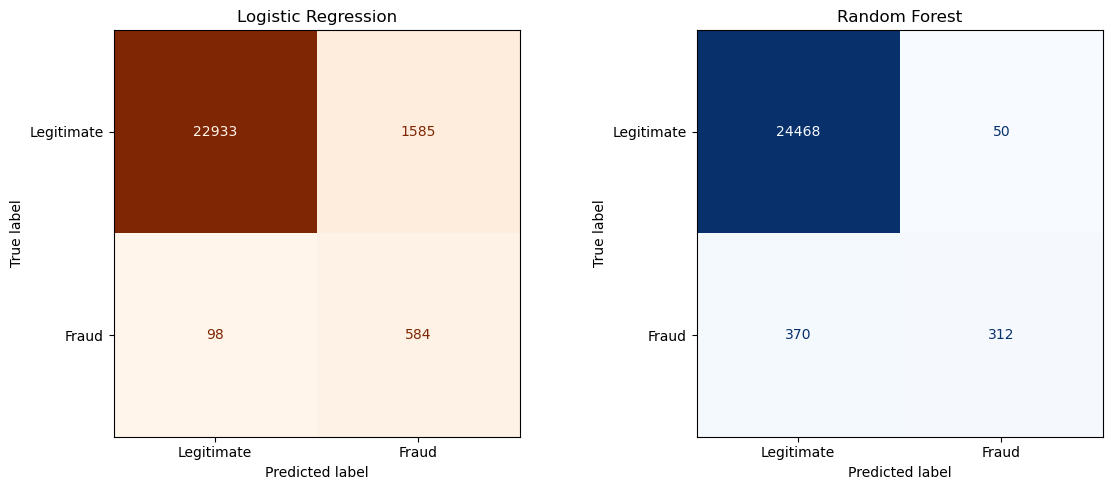

In [31]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate predictions
lr_pred = lr_pipeline.predict(x_test)
rf_pred = rf_pipeline.predict(x_test)

# Create confusion matrices
cm_lr = confusion_matrix(y_test, lr_pred)
cm_rf = confusion_matrix(y_test, rf_pred)

# Print numerical results

print("\nLogistic Regression Confusion Matrix:")
print(cm_lr)

print("Random Forest Confusion Matrix:")
print(cm_rf)

# Plot both confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression
ConfusionMatrixDisplay(confusion_matrix=cm_lr,display_labels=["Legitimate", "Fraud"]).plot(cmap="Oranges", ax=axes[0], colorbar=False)

axes[0].set_title("Logistic Regression")

# Random Forest
ConfusionMatrixDisplay(confusion_matrix=cm_rf,display_labels=["Legitimate", "Fraud"]).plot(cmap="Blues", ax=axes[1], colorbar=False)

axes[1].set_title("Random Forest")
plt.tight_layout()
plt.show()

###### Logistic Regression: Good at catching fraud, but it achieves this by generating many false alarms.
###### Random Forest: Very precise when it predicts fraud, but it misses a large proportion of fraudulent transactions.

#### Feature Importance

In [32]:
import pandas as pd

# Extract the logistic regression model from the pipeline
lr_model = lr_pipeline.named_steps["classifier"]

# Get feature names from the preprocessing step
feature_names = lr_pipeline.named_steps["preprocessor"].get_feature_names_out()

# Get coefficients
coefficients = lr_model.coef_[0]

# Create a DataFrame for easy viewing
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Importance (abs)": abs(coefficients)
}).sort_values(by="Importance (abs)", ascending=False)

feature_importance.head(10)


,Feature,Coefficient,Importance (abs)
0,numeric__amount_to_avg_ratio,1.350763,1.350763
1,numeric__transaction_velocity_1h,0.902431,0.902431
7,binary__is_cross_border,0.808908,0.808908
8,binary__is_new_device,0.707467,0.707467
23,categorical__merchant_category_Gambling/Gaming,0.604486,0.604486
33,categorical__merchant_category_Utilities,-0.486738,0.486738
34,categorical__merchant_category_Wire Transfer,0.471669,0.471669
21,categorical__merchant_category_Crypto Exchange,0.404052,0.404052
49,categorical__transaction_country_US,-0.383499,0.383499
32,categorical__merchant_category_Travel,-0.348609,0.348609


The feature with the most important influence on fraud detection is the amount to average ratio.

In [37]:
import pandas as pd

# Extract the logistic regression model from the pipeline
rf_model = rf_pipeline.named_steps["classifier"]

# Get feature names from the preprocessing step
rf_feature_names = rf_pipeline.named_steps["preprocessor"].get_feature_names_out()

# Get importances
rf_importances = rf_model.feature_importances_

# Create a DataFrame for easy viewing
rf_feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_importances,
}).sort_values(by="Importance", ascending=False)

rf_feature_importance.head(10)

,Feature,Importance
1,numeric__transaction_velocity_1h,0.260037
0,numeric__amount_to_avg_ratio,0.207807
4,numeric__amount_deviation_30d_usd,0.116046
3,numeric__amount_vs_personal_baseline,0.071045
6,numeric__account_age_days,0.037565
2,numeric__rate_to_usd,0.027298
11,temporal__hour_sin,0.025959
12,temporal__hour_cos,0.025321
9,temporal__month_cos,0.020414
10,temporal__month_sin,0.019821


The feature with the most important influence on fraud detection in the random forest model is the transaction velocity.

### Key Insights

Behavioral deviation is a major fraud signal: Amount-to-average ratio emerged as the most influential Logistic Regression feature, showing the importance of comparing transactions with normal customer behavior. 

Transaction velocity is strongly associated with fraud: It recorded the strongest reported correlation with the fraud indicator (0.577). 

New-device and cross-border activity provide useful risk signals and appear among the important model features. 

Fraud detection involves a precision-recall trade-off: Logistic Regression identifies more fraud cases, whereas Random Forest provides substantially higher precision at the reported default operating point. 

Threshold selection matters: increasing recall substantially reduces precision, meaning the final operating threshold should reflect Finlora's tolerance for missed fraud versus unnecessary investigations. 


#### Recommendations

Implement behavior-based fraud detection: Assess transactions using customer spending patterns, transaction velocity, device status, cross-border activity, and other relevant risk indicators. 

Prioritize alerts based on risk: Use model-generated fraud scores to rank suspicious transactions, allowing investigators to focus on higher-risk cases first.

Optimize the decision threshold: Select a threshold that balances fraud detection with false positives, based on Finlora’s business priorities and risk tolerance. 

Adopt a combined modelling approach: The combined risk score can support more balanced fraud detection while reducing the limitations associated with relying on either model individually.

Continuously monitor model performance: Regularly assess precision, recall, and false-positive rates to ensure the model remains effective as transaction behavior changes.


#### Conclusion

The Finlora Fraud Detection project demonstrates that a data-driven, behavior-based approach can provide a more informative foundation for fraud monitoring than relying solely on static rules. The analysis identified transaction velocity, unusual spending relative to historical behavior, cross-border activity, and new-device usage as important fraud-related signals. 

Logistic Regression and Random Forest demonstrate different strengths, with Logistic Regression providing higher recall at the reported baseline and Random Forest substantially higher precision. Threshold analysis further shows that the most appropriate solution depends on Finlora's desired balance between detecting fraud and minimizing false positives. 


### Deployment to Streamlit

In [40]:
x_train.columns

Index(['account_type_y', 'kyc_tier_y', 'merchant_category', 'channel',
       'currency_y', 'amount_to_avg_ratio', 'transaction_velocity_1h',
       'transaction_country', 'home_country_y', 'is_cross_border',
       'is_new_device', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos',
       'rate_to_usd', 'amount_vs_personal_baseline',
       'amount_deviation_30d_usd', 'new_device_amount_anomaly',
       'account_age_days', 'month_sin', 'month_cos'],
      dtype='object')

In [42]:
for col in categorical_features:
    print(f"\n{col}:")
    print(x_train[col].unique())


account_type_y:
['Individual' 'Business']

kyc_tier_y:
['Tier1_Basic' 'Tier2_Verified' 'Tier3_Enhanced']

merchant_category:
['Utilities' 'Restaurants' 'Retail' 'ATM Withdrawal' 'Subscription/SaaS'
 'Healthcare' 'Wire Transfer' 'Electronics' 'Payroll Transfer' 'Groceries'
 'Travel' 'Insurance' 'P2P Transfer' 'Gambling/Gaming' 'Crypto Exchange']

channel:
['Mobile App' 'Web Dashboard' 'USSD' 'Card Not Present' 'API/Integration'
 'Card Present']

currency_y:
['NGN' 'EUR' 'USD' 'GBP']

transaction_country:
['NG' 'DE' 'US' 'FR' 'GB']

home_country_y:
['NG' 'DE' 'US' 'FR' 'GB']


In [52]:
for col in categorical_features:
    print(f"\n{col}:")
    print(sorted(x_train[col].dropna().unique()))


account_type_y:
['Business', 'Individual']

kyc_tier_y:
['Tier1_Basic', 'Tier2_Verified', 'Tier3_Enhanced']

merchant_category:
['ATM Withdrawal', 'Crypto Exchange', 'Electronics', 'Gambling/Gaming', 'Groceries', 'Healthcare', 'Insurance', 'P2P Transfer', 'Payroll Transfer', 'Restaurants', 'Retail', 'Subscription/SaaS', 'Travel', 'Utilities', 'Wire Transfer']

channel:
['API/Integration', 'Card Not Present', 'Card Present', 'Mobile App', 'USSD', 'Web Dashboard']

currency_y:
['EUR', 'GBP', 'NGN', 'USD']

transaction_country:
['DE', 'FR', 'GB', 'NG', 'US']

home_country_y:
['DE', 'FR', 'GB', 'NG', 'US']


In [54]:
import streamlit as st
import pandas as pd
import numpy as np
import joblib


# ==========================================
# PAGE CONFIGURATION
# ==========================================

st.set_page_config(
    page_title="Fraud Detection System",
    page_icon="🔍",
    layout="wide"
)

st.title("🔍 Transaction Fraud Detection System")

st.write(
    "Enter the transaction details below. "
    "The system will evaluate the transaction using both "
    "Logistic Regression and Random Forest."
)


# ==========================================
# LOAD MODELS
# ==========================================

@st.cache_resource
def load_models():
    lr_pipeline = joblib.load("lr_pipeline.pkl")
    rf_pipeline = joblib.load("rf_pipeline.pkl")

    return lr_pipeline, rf_pipeline


lr_pipeline, rf_pipeline = load_models()


# ==========================================
# INPUT FORM
# ==========================================

with st.form("fraud_form"):

    # ======================================
    # 1. CATEGORICAL FEATURES
    # ======================================

    st.subheader("1. Account & Transaction Details")

    col1, col2, col3 = st.columns(3)

    with col1:
        account_type = st.selectbox(
            "Account Type",
            [
                "Business",
                "Individual"
            ]
        )

        kyc_tier = st.selectbox(
            "KYC Tier",
            [
                "Tier1_Basic",
                "Tier2_Verified",
                "Tier3_Enhanced"
            ]
        )

        merchant_category = st.selectbox(
            "Merchant Category",
            [
                "ATM Withdrawal",
                "Crypto Exchange",
                "Electronics",
                "Gambling/Gaming",
                "Groceries",
                "Healthcare",
                "Insurance",
                "P2P Transfer",
                "Payroll Transfer",
                "Restaurants",
                "Retail",
                "Subscription/SaaS",
                "Travel",
                "Utilities",
                "Wire Transfer"
            ]
        )

    with col2:
        channel = st.selectbox(
            "Transaction Channel",
            [
                "API/Integration",
                "Card Not Present",
                "Card Present",
                "Mobile App",
                "USSD",
                "Web Dashboard"
            ]
        )

        currency = st.selectbox(
            "Currency",
            [
                "EUR",
                "GBP",
                "NGN",
                "USD"
            ]
        )

    with col3:
        transaction_country = st.selectbox(
            "Transaction Country",
            [
                "DE",
                "FR",
                "GB",
                "NG",
                "US"
            ]
        )

        home_country = st.selectbox(
            "Home Country",
            [
                "DE",
                "FR",
                "GB",
                "NG",
                "US"
            ]
        )


    # ======================================
    # 2. NUMERIC FEATURES
    # ======================================

    st.subheader("2. Transaction Behaviour")

    col1, col2, col3 = st.columns(3)

    with col1:
        amount_to_avg_ratio = st.number_input(
            "Amount to Average Ratio",
            min_value=0.0,
            value=1.0,
            step=0.1
        )

        transaction_velocity_1h = st.number_input(
            "Transaction Velocity (1 Hour)",
            min_value=0.0,
            value=0.0,
            step=1.0
        )

        rate_to_usd = st.number_input(
            "Exchange Rate to USD",
            min_value=0.0,
            value=1.0
        )

    with col2:
        amount_vs_personal_baseline = st.number_input(
            "Amount vs Personal Baseline",
            value=0.0
        )

        amount_deviation_30d_usd = st.number_input(
            "30-Day Amount Deviation (USD)",
            value=0.0
        )

    with col3:
        new_device_amount_anomaly = st.number_input(
            "New Device Amount Anomaly",
            value=0.0
        )

        account_age_days = st.number_input(
            "Account Age (Days)",
            min_value=0,
            value=365,
            step=1
        )


    # ======================================
    # 3. BINARY FEATURES
    # ======================================

    st.subheader("3. Security Indicators")

    col1, col2 = st.columns(2)

    with col1:
        is_cross_border = st.checkbox(
            "Cross-border transaction"
        )

    with col2:
        is_new_device = st.checkbox(
            "Transaction from a new device"
        )


    # ======================================
    # 4. TEMPORAL FEATURES
    # ======================================

    st.subheader("4. Transaction Time")

    col1, col2, col3 = st.columns(3)

    with col1:
        hour = st.slider(
            "Hour of Day",
            min_value=0,
            max_value=23,
            value=12
        )

    with col2:
        day_of_week = st.selectbox(
            "Day of Week",
            [
                "Monday",
                "Tuesday",
                "Wednesday",
                "Thursday",
                "Friday",
                "Saturday",
                "Sunday"
            ]
        )

    with col3:
        month = st.selectbox(
            "Month",
            list(range(1, 13))
        )


    # ======================================
    # SUBMIT BUTTON
    # ======================================

    submitted = st.form_submit_button(
        "🔍 Analyse Transaction",
        type="primary"
    )


# ==========================================
# PROCESS INPUT AFTER SUBMISSION
# ==========================================

if submitted:

    # ======================================
    # CONVERT BINARY FEATURES
    # ======================================

    cross_border_value = int(is_cross_border)
    new_device_value = int(is_new_device)


    # ======================================
    # CREATE TEMPORAL FEATURES
    # ======================================

    # Hour encoding
    hour_sin = np.sin(2 * np.pi * hour / 24)
    hour_cos = np.cos(2 * np.pi * hour / 24)

    # Day-of-week mapping
    day_mapping = {
        "Monday": 0,
        "Tuesday": 1,
        "Wednesday": 2,
        "Thursday": 3,
        "Friday": 4,
        "Saturday": 5,
        "Sunday": 6
    }

    dow = day_mapping[day_of_week]

    # Day-of-week encoding
    dow_sin = np.sin(2 * np.pi * dow / 7)
    dow_cos = np.cos(2 * np.pi * dow / 7)

    # Month encoding
    # Matches your training transformation
    month_sin = np.sin(2 * np.pi * month / 12)
    month_cos = np.cos(2 * np.pi * month / 12)


    # ======================================
    # CREATE INPUT DATAFRAME
    # ======================================

    input_data = pd.DataFrame({

        # Categorical
        "account_type_y": [account_type],
        "kyc_tier_y": [kyc_tier],
        "merchant_category": [merchant_category],
        "channel": [channel],
        "currency_y": [currency],
        "transaction_country": [transaction_country],
        "home_country_y": [home_country],

        # Numeric
        "amount_to_avg_ratio": [amount_to_avg_ratio],
        "transaction_velocity_1h": [transaction_velocity_1h],
        "rate_to_usd": [rate_to_usd],
        "amount_vs_personal_baseline": [
            amount_vs_personal_baseline
        ],
        "amount_deviation_30d_usd": [
            amount_deviation_30d_usd
        ],
        "new_device_amount_anomaly": [
            new_device_amount_anomaly
        ],
        "account_age_days": [account_age_days],

        # Binary
        "is_cross_border": [cross_border_value],
        "is_new_device": [new_device_value],

        # Temporal
        "month_cos": [month_cos],
        "month_sin": [month_sin],
        "hour_sin": [hour_sin],
        "hour_cos": [hour_cos],
        "dow_sin": [dow_sin],
        "dow_cos": [dow_cos]
    })


    # ======================================
    # MODEL PREDICTIONS
    # ======================================

    try:

        # Predictions
        lr_prediction = lr_pipeline.predict(input_data)[0]
        rf_prediction = rf_pipeline.predict(input_data)[0]

        # Probabilities
        lr_probability = lr_pipeline.predict_proba(
            input_data
        )[0][1]

        rf_probability = rf_pipeline.predict_proba(
            input_data
        )[0][1]


        # ==================================
        # RESULTS
        # ==================================

        st.divider()
        st.header("Prediction Results")

        col1, col2 = st.columns(2)


        # ==================================
        # LOGISTIC REGRESSION RESULT
        # ==================================

        with col1:

            st.subheader("Logistic Regression")

            if lr_prediction == 1:
                st.error("⚠️ FRAUD DETECTED")
            else:
                st.success("✅ LEGITIMATE TRANSACTION")

            st.metric(
                "Fraud Probability",
                f"{lr_probability:.2%}"
            )


        # ==================================
        # RANDOM FOREST RESULT
        # ==================================

        with col2:

            st.subheader("Random Forest")

            if rf_prediction == 1:
                st.error("⚠️ FRAUD DETECTED")
            else:
                st.success("✅ LEGITIMATE TRANSACTION")

            st.metric(
                "Fraud Probability",
                f"{rf_probability:.2%}"
            )


        # ==================================
        # MODEL COMPARISON
        # ==================================

        st.subheader("Model Comparison")

        comparison = pd.DataFrame({
            "Model": [
                "Logistic Regression",
                "Random Forest"
            ],
            "Fraud Probability": [
                lr_probability,
                rf_probability
            ]
        })

        st.bar_chart(
            comparison.set_index("Model")
        )


        # ==================================
        # MODEL AGREEMENT
        # ==================================

        if lr_prediction == rf_prediction:

            if lr_prediction == 1:

                st.warning(
                    "⚠️ Both models classify this "
                    "transaction as fraudulent."
                )

            else:

                st.success(
                    "✅ Both models classify this "
                    "transaction as legitimate."
                )

        else:

            st.warning(
                "⚠️ The two models disagree "
                "on this transaction."
            )


        # ==================================
        # INPUT PREVIEW
        # ==================================

        with st.expander(
            "View transaction features"
        ):

            st.dataframe(
                input_data,
                use_container_width=True
            )


    except Exception as e:

        st.error(
            f"Prediction failed: {e}"
        )

2026-10-06 20:36:25.029 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-06 20:36:25.031 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-06 20:36:25.031 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-06 20:36:25.033 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-06 20:36:25.034 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-06 20:36:25.035 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-06 20:36:25.036 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-06 20:36:25.038 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

In [55]:
print(lr_pipeline.classes_)
print(rf_pipeline.classes_)

[0 1]
[0 1]


In [56]:
import joblib

joblib.dump(
    lr_pipeline,
    "lr_pipeline.pkl"
)

joblib.dump(
    rf_pipeline,
    "rf_pipeline.pkl"
)

['rf_pipeline.pkl']